# PyWake-Simulation vs. ZXTM-LiDAR auf T07 (Hill of Towie)

**Ziel:** Für einen gewählten Zeitraum die Situation "T03 lenkt seinen Nachlauf an T07 vorbei" mit PyWake simulieren und mit den Messungen des ZXTM-LiDARs auf T07 vergleichen. Dieses Notebook ist die Grundlage für eine mögliche Challenge-Auswertung.

**Ablauf:**

1. Einstellungen
2. Windpark-Setup (Turbinenpositionen, Turbinenmodell)
3. Turbinendaten (Fastlog) laden und auf 1-Minuten-Mittel bringen
4. PyWake-Simulation (mit und ohne Wake Steering)
5. ZXTM-Daten laden und bereinigen
6. Geometrie: Wo liegen die Messpunkte?
7. PyWake an den Messpunkten auswerten und auf die Strahlrichtung projizieren (LOS)
8. Messwerte dazunehmen
9. Rotor Equivalent Wind Speed (REWS), Variante A
10. Vergleich und Kennzahlen (Bias, RMSE, NRMSE, Score)
11. Plots

Alle Zeitstempel sind UTC. Das Notebook läuft nach einem Kernel-Neustart von oben nach unten durch.

## 1. Einstellungen

Alle Werte, die man für Experimente ändern möchte, stehen hier an einer Stelle.

- `FREQ`: Mittelungsintervall. Jede Distanz des ZXTM wird nur einige Sekunden pro Minute gemessen, deshalb sind 1-Minuten-Mittel verrauscht. `"10min"` ergibt ruhigere Kurven, aber weniger Zeitpunkte.
- `WAKE_K`, `TI`: Parameter des Wake-Modells. Hill of Towie hat überdurchschnittlich hohe Turbulenz, die Werte sind vorläufig.
- `SHEAR_ALPHA`: Exponent der Windscherung. 0 bedeutet "überall gleicher Wind". Vorläufig 0.2, später aus dem ZX300 bestimmen.
- `WD_WINDOW`: Steering-Fenster für T03 → T07 (laut Präsentation 192–224°). Nur aktiv, wenn `APPLY_WD_FILTER = True`.

In [1]:
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyproj import Transformer

from py_wake.deflection_models.jimenez import JimenezWakeDeflection
from py_wake.flow_map import HorizontalGrid, Points
from py_wake.literature.gaussian_models import Bastankhah_PorteAgel_2014
from py_wake.site import UniformSite
from py_wake.site.shear import PowerShear
from py_wake.wind_turbines.generic_wind_turbines import GenericWindTurbine

from hot_open.fastlog_helpers import load_hot_fl_data
from hot_open.lidar_helpers import load_zx_lidar_fl_data
from hot_open.settings import get_data_dir, get_filestore_dir
from hot_open.sourcing_data import ensure_hot_data_files

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")

# Zeitraum (wie in der Referenzabbildung der RES-Präsentation)
START = pd.Timestamp("2026-02-20 00:00", tz="UTC")
END_EXCL = pd.Timestamp("2026-02-20 04:30", tz="UTC")

# Mittelung
FREQ = "1min"

# Wake-Modell und Anströmung
WAKE_K = 0.0324555
TI = 0.1
SHEAR_ALPHA = 0.2
HUB_H = 59.0
ROTOR_R = 41.0

# Optionaler Filter auf das Steering-Fenster
APPLY_WD_FILTER = False
WD_WINDOW = (192.0, 224.0)

# ZXTM-Geometrie
RANGES_M = [85.0, 126.0, 208.0]              # verwendete Messdistanzen (wie im RES-Skript)
HEIGHTS_M = [26.2, 42.6, 59.0, 75.4, 91.8]   # Mitten der 5 Rotor-Höhenstreifen
SLICE_HALF = 8.2                             # halbe Streifenhöhe (82 m / 5 / 2)
SIDES = ["Right", "Left"]                    # rechts = West, links = Ost (bei Wind aus SSW)
HALF_ANGLE_DEG = 15.0                        # Kegel-Halbwinkel des ZXTM
LIDAR_Z = HUB_H + 3.2                        # Deployment-Bericht: 3.2 m über der Rotorachse
MIN_COUNT = 500                              # Mindestanzahl gültiger Werte, damit ein Streifen für die REWS verwendet wird

# Fastlog-Tags des Dynamic-Yaw-Controllers (True North)
YAW = "computed_driver_pre_processed_yaw_direction_true_degrees"
WD = "computed_core_post_processed_consensus_wind_direction_true_degrees"
TOGGLE = "computed_driver_post_processed_toggle_state"
WS_OFFSET = "computed_core_post_processed_core_wake_steering_offset_degrees"

LOS_COL = "{side} LOS Speed (m/s) at Rotor Segment Height {h}m"

c:\Users\ryan.feusi\hill-of-towie-open-source-analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Windpark-Setup

Turbinenpositionen aus den Metadaten (Längen-/Breitengrad) werden in Meter umgerechnet (UTM-Zone 30N), mit dem Ursprung in der Südwestecke des Parks. Die Koordinaten stimmen auf unter einen halben Meter mit denen in der FLORIS-Konfiguration des Repos überein.

Die Siemens SWT-2.3-VS-82 ist in PyWake nicht hinterlegt. `GenericWindTurbine` erzeugt eine plausible Leistungs- und Schubkurve aus Durchmesser, Nabenhöhe und Nennleistung. Das ist eine Näherung.

In [2]:
ensure_hot_data_files(["Hill_of_Towie_turbine_metadata.csv"])
turbine_metadata = pd.read_csv(get_data_dir() / "Hill_of_Towie_turbine_metadata.csv")
names = turbine_metadata["Turbine Name"].to_list()

transformer = Transformer.from_crs("EPSG:4326", "EPSG:32630", always_xy=True)
utm_x, utm_y = transformer.transform(turbine_metadata["Longitude"].to_numpy(),
                                     turbine_metadata["Latitude"].to_numpy())
x = utm_x - utm_x.min()
y = utm_y - utm_y.min()

i01, i03, i07 = names.index("T01"), names.index("T03"), names.index("T07")
x07, y07 = x[i07], y[i07]

swt23 = GenericWindTurbine(name="SWT-2.3-VS-82", diameter=2 * ROTOR_R, hub_height=HUB_H,
                           power_norm=2300, turbulence_intensity=TI)

print({n: (round(x[i], 1), round(y[i], 1)) for n, i in [("T01", i01), ("T03", i03), ("T07", i07)]})

INFO hot_open.sourcing_data: ensure_hot_data_files: all 1 requested files already present at C:\Users\ryan.feusi\temp\hill-of-towie-open-source-analysis\data (and no missing small files in cached metadata), skipping download


{'T01': (np.float64(133.7), np.float64(328.6)), 'T03': (np.float64(0.0), np.float64(646.6)), 'T07': (np.float64(188.0), np.float64(987.4))}


## 3. Turbinendaten laden und auf `FREQ` mitteln

Wir laden die hochaufgelösten Fastlog-Daten (etwa 1 Hz) von T01, T03 und T07.

**Unsere Schritte:**

- **True North:** Die rohen Siemens-Richtungen sind nicht auf den geografischen Norden kalibriert. Wir verwenden deshalb die Tags des Dynamic-Yaw-Controllers, die auf `_true_degrees` enden.
- **Stolperstein:** `load_hot_fl_data` braucht den Filestore-Ordner (`get_filestore_dir()`), nicht den normalen Datenordner.
- **Zirkuläre Mittelung:** Richtungen dürfen nicht normal gemittelt werden (Mittel von 359° und 1° ist 0°, nicht 180°). Wir mitteln sie als Einheitsvektoren.
- **Gierwinkel von T03:** `Windrichtung − Gondelrichtung`. Positiv heißt "gegen den Uhrzeigersinn verdreht", das ist die Konvention von PyWake.
- **Anströmung:** Windgeschwindigkeit (Gondel-Anemometer) und Consensus-Windrichtung von T01 werden für den ganzen Park verwendet (`UniformSite`). Das ist die größte Vereinfachung des Setups.

In [3]:
fl = load_hot_fl_data(
    data_dir=get_filestore_dir(),
    wtg_numbers=[1, 3, 7],
    start_dt=START,
    end_dt_excl=END_EXCL,
    extra_tags=[YAW, WD, TOGGLE, WS_OFFSET],
)


def circ_mean_resample(series, freq):
    # Zirkulärer Mittelwert: Winkel als Einheitsvektoren mitteln, dann zurück in Grad
    rad = np.deg2rad(series)
    return np.rad2deg(np.arctan2(np.sin(rad).resample(freq).mean(),
                                 np.cos(rad).resample(freq).mean())) % 360


def circ_diff(a, b):
    # Zirkuläre Differenz a - b im Bereich [-180, 180)
    return (a - b + 180) % 360 - 180


m = pd.DataFrame({
    "ws_t01":     fl[("T01", "AcWindSp_AcWindSp")].resample(FREQ).mean(),
    "wd_t01":     circ_mean_resample(fl[("T01", WD)], FREQ),
    "wd_t03":     circ_mean_resample(fl[("T03", WD)], FREQ),
    "yaw_t03":    circ_mean_resample(fl[("T03", YAW)], FREQ),
    "yaw_t07":    circ_mean_resample(fl[("T07", YAW)], FREQ),
    "offset_t03": fl[("T03", WS_OFFSET)].resample(FREQ).mean(),
    "toggle_t03": fl[("T03", TOGGLE)].resample(FREQ).mean(),
    "p_t03":      fl[("T03", "ActPower_Value")].resample(FREQ).mean(),
    "p_t07":      fl[("T07", "ActPower_Value")].resample(FREQ).mean(),
})
m["yaw_mis_t03"] = circ_diff(m["wd_t03"], m["yaw_t03"])
m = m.dropna(subset=["ws_t01", "wd_t01", "yaw_mis_t03", "yaw_t07"])
m["toggle_on"] = m["toggle_t03"] > 0.5
m.head()

INFO hot_open.fastlog_helpers: Reading: C:\Users\ryan.feusi\temp\hill-of-towie-open-source-analysis\cache\fl_resampled\HOT\2304510\20260220_EIlqz_Z3Vc3ki-UJiOMVKhMeDnJLhA3m.parquet
INFO hot_open.fastlog_helpers: Reading: C:\Users\ryan.feusi\temp\hill-of-towie-open-source-analysis\cache\fl_resampled\HOT\2304512\20260220_OXg6c4tKlhtGN-YBZ90MA9rBoixaCNpU.parquet
INFO hot_open.fastlog_helpers: Reading: C:\Users\ryan.feusi\temp\hill-of-towie-open-source-analysis\cache\fl_resampled\HOT\2304516\20260220_Fb8AESKTyNWUf-OuDVGMiizyMgkYjxdx.parquet


,ws_t01,wd_t01,wd_t03,yaw_t03,yaw_t07,offset_t03,toggle_t03,p_t03,p_t07,yaw_mis_t03,toggle_on
timestamp,,,,,,,,,,,
2026-02-20 00:00:00+00:00,7.446664,199.976540,197.045234,191.348460,191.634395,-9.733594,0.0,788.345000,1012.862500,5.696774,False
2026-02-20 00:01:00+00:00,7.068918,197.170615,196.060383,194.990774,192.332350,-11.538281,0.0,627.024167,641.453333,1.069610,False
2026-02-20 00:02:00+00:00,8.368375,199.575273,195.778060,195.039774,194.051312,-10.515625,0.0,594.147500,659.043333,0.738287,False
2026-02-20 00:03:00+00:00,7.843628,199.157655,195.560872,194.313807,194.150395,-8.661719,0.0,577.889167,870.745833,1.247065,False
2026-02-20 00:04:00+00:00,7.813193,201.322858,198.084439,192.867273,194.150395,-13.370313,0.0,768.601667,917.605833,5.217166,False


### Kontrolle: Richtungen und Steering-Phasen (Nachbau der Referenzabbildung)

In den grünen Phasen weicht die Gondel von T03 bewusst von der Windrichtung ab.

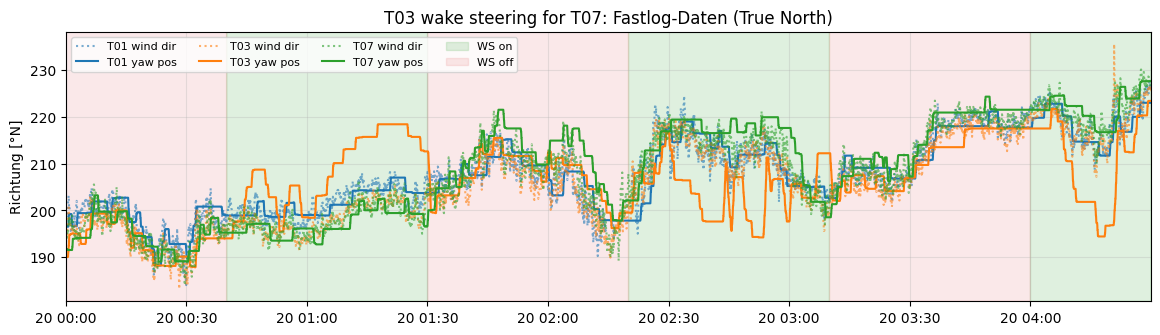

In [4]:
colors = {"T01": "tab:blue", "T03": "tab:orange", "T07": "tab:green"}
fig, ax = plt.subplots(figsize=(14, 3.5))
for name, c in colors.items():
    ax.plot(fl.index, fl[(name, WD)], color=c, ls=":", alpha=0.6, label=f"{name} wind dir")
    ax.plot(fl.index, fl[(name, YAW)], color=c, label=f"{name} yaw pos")
toggle = fl[("T03", TOGGLE)]
ax.fill_between(fl.index, 0, 1, where=(toggle == 1), transform=ax.get_xaxis_transform(),  # type: ignore
                color="tab:green", alpha=0.15, label="WS on")
ax.fill_between(fl.index, 0, 1, where=(toggle == 0), transform=ax.get_xaxis_transform(),  # type: ignore
                color="tab:red", alpha=0.10, label="WS off")
ax.set_ylabel("Richtung [°N]")
ax.set_title("T03 wake steering for T07: Fastlog-Daten (True North)")
ax.legend(ncol=4, fontsize=8)
ax.grid(alpha=0.3)
ax.margins(x=0)
plt.show()

## 4. PyWake-Simulation

- **Site:** einheitliche Anströmung mit Turbulenzintensität `TI` und Windscherung nach Potenzgesetz `ws(h) = ws_Nabe · (h / 59 m)^α`.
- **Wake-Modell:** Bastankhah & Porté-Agel (2014), Gauß-förmiger Nachlauf, Parameter `k`.
- **Deflection-Modell:** Jiménez, lenkt den Nachlauf bei schräg gestellter Turbine seitlich ab. Ohne dieses Modell hätte der Gierwinkel keinen Einfluss auf die Lage des Nachlaufs.
- **Zeitreihen-Modus:** `time=...` sorgt dafür, dass `wd[i]` und `ws[i]` als Paar gerechnet werden, ein Fall pro Zeitschritt.
- **Gierwinkel:** Matrix mit einer Zeile pro Turbine und einer Spalte pro Zeitschritt. Nur T03 bekommt seinen gemessenen Gierwinkel, alle anderen gelten als perfekt ausgerichtet.
- **Zwei Simulationen:** `sim_steer` (mit gemessenem Gierwinkel von T03) und `sim_ref` (alle Turbinen im Wind). Die Differenz zeigt, was das Steering laut PyWake bewirkt.

In [5]:
site = UniformSite(p_wd=[1], ti=TI, shear=PowerShear(h_ref=HUB_H, alpha=SHEAR_ALPHA))
wf_model = Bastankhah_PorteAgel_2014(site, swt23, k=WAKE_K, deflectionModel=JimenezWakeDeflection())

time = m.index.tz_convert(None).to_numpy()   # PyWake bekommt zeitzonenfreie UTC-Zeitstempel
wd_in = m["wd_t01"].to_numpy()
ws_in = m["ws_t01"].to_numpy()

yaw = np.zeros((len(x), len(m)))
yaw[i03, :] = m["yaw_mis_t03"].to_numpy()

sim_steer = wf_model(x, y, wd=wd_in, ws=ws_in, time=time, yaw=yaw, tilt=0)
sim_ref = wf_model(x, y, wd=wd_in, ws=ws_in, time=time, yaw=np.zeros_like(yaw), tilt=0)

## 5. ZXTM-Daten laden und bereinigen

- **Achtung:** `load_zx_lidar_fl_data` braucht `get_data_dir() / "lidar_data"` (fehler im script).
- **Ungültige Werte:** Laut Data Dictionary sind alle Werte von 9987 bis 9999 Platzhalter. `remove_bad_values=True` entfernt nur 9999 und 9991, deshalb entfernen wir die übrigen selbst (`mask`).
- **Datenaufbau:** Jede Zeile ist eine Sekunde Messung auf **einer** Distanz (`Range (m)`), mit 10 LOS-Werten (5 Höhenstreifen × 2 Seiten). Der LiDAR verweilt einige Sekunden auf einer Distanz und wechselt dann zur nächsten.
- **Abdeckung:** Nicht jede Distanz erreicht jeden Höhenstreifen. Die Tabelle zeigt, wie viele gültige Werte es pro Distanz und Spalte gibt.

In [6]:
zxtm = load_zx_lidar_fl_data(
    data_dir=get_data_dir() / "lidar_data",
    lidar_unit_id="5060",
    start_dt=START,
    end_dt_excl=END_EXCL,
    remove_bad_values=True,
)

num_cols = zxtm.select_dtypes(include="number").columns
zxtm[num_cols] = zxtm[num_cols].mask((zxtm[num_cols] >= 9987) & (zxtm[num_cols] <= 9999))

los_cols = [LOS_COL.format(side=s, h=h) for s in SIDES for h in HEIGHTS_M]
coverage = zxtm.groupby("Range (m)")[los_cols].count()
coverage.T

INFO hot_open.sourcing_data: ensure_extracted: lidar_data.zip already extracted (sentinel C:\Users\ryan.feusi\temp\hill-of-towie-open-source-analysis\data\lidar_data\timeseries present), skipping
INFO hot_open.lidar_helpers: Reading 1 fastlog parquet files from C:\Users\ryan.feusi\temp\hill-of-towie-open-source-analysis\data\lidar_data\timeseries\5060
Reading 5060 fastlog parquet files: 100%|██████████| 1/1 [00:00<00:00,  4.72it/s]
INFO hot_open.lidar_helpers: Writing: C:\Users\ryan.feusi\temp\hill-of-towie-open-source-analysis\cache\lidar_raw\5060_20260220000000_20260220043000.parquet
INFO hot_open.lidar_helpers: Reading: C:\Users\ryan.feusi\temp\hill-of-towie-open-source-analysis\cache\lidar_raw\5060_20260220000000_20260220043000.parquet


Range (m),10,48,64,85,126,208
Right LOS Speed (m/s) at Rotor Segment Height 26.2m,0,0,0,0,24,775
Right LOS Speed (m/s) at Rotor Segment Height 42.6m,0,0,2,1527,1498,1300
Right LOS Speed (m/s) at Rotor Segment Height 59.0m,3,1756,1819,1819,1737,1393
Right LOS Speed (m/s) at Rotor Segment Height 75.4m,0,1346,2210,2125,2001,1642
Right LOS Speed (m/s) at Rotor Segment Height 91.8m,0,0,0,0,2195,2029
Left LOS Speed (m/s) at Rotor Segment Height 26.2m,0,0,0,0,24,775
Left LOS Speed (m/s) at Rotor Segment Height 42.6m,0,0,2,1527,1498,1300
Left LOS Speed (m/s) at Rotor Segment Height 59.0m,3,1756,1819,1819,1737,1393
Left LOS Speed (m/s) at Rotor Segment Height 75.4m,0,1346,2210,2125,2001,1642
Left LOS Speed (m/s) at Rotor Segment Height 91.8m,0,0,0,0,2195,2029


### Welche Höhenstreifen verwenden wir pro Distanz?

Ein Streifen wird für die REWS verwendet, wenn auf **beiden** Seiten mindestens `MIN_COUNT` gültige Werte vorliegen. Bei unserem Zeitraum ergibt das: 85 m → 3 Streifen, 126 m → 4 Streifen, 208 m → 5 Streifen, insgesamt 24 Messpunkte.

In [7]:
REWS_HEIGHTS = {
    r: [h for h in HEIGHTS_M
        if min(coverage.loc[r, LOS_COL.format(side=s, h=h)] for s in SIDES) >= MIN_COUNT]
    for r in RANGES_M
}
REWS_HEIGHTS

{85.0: [42.6, 59.0, 75.4],
 126.0: [42.6, 59.0, 75.4, 91.8],
 208.0: [26.2, 42.6, 59.0, 75.4, 91.8]}

### Wie oft wird jede Distanz gemessen?

Der Median der Abstände liegt bei etwa 1 s (innerhalb eines Messblocks), das 90-%-Quantil zeigt die Lücken zwischen den Blöcken. Wichtig für die Wahl von `FREQ`.

In [8]:
hub_right = LOS_COL.format(side="Right", h=59.0)
for r, g in zxtm.groupby("Range (m)"):
    valid = g[hub_right].dropna()
    if valid.empty:
        continue
    per_interval = valid.resample(FREQ).count()
    gaps = valid.index.to_series().diff().dt.total_seconds()
    print(f"{r:>5} m: {len(valid):5d} Werte | pro {FREQ} Ø {per_interval.mean():5.1f}, "
          f"ohne Wert {(per_interval == 0).mean():5.1%} | Lücke Median {gaps.median():4.1f} s, "
          f"90%-Quantil {gaps.quantile(0.9):6.1f} s")

   10 m:     3 Werte | pro 1min Ø   3.0, ohne Wert  0.0% | Lücke Median  1.0 s, 90%-Quantil    1.0 s
   48 m:  1756 Werte | pro 1min Ø   6.5, ohne Wert  0.7% | Lücke Median  1.0 s, 90%-Quantil   29.2 s
   64 m:  1819 Werte | pro 1min Ø   6.7, ohne Wert  1.1% | Lücke Median  1.0 s, 90%-Quantil   29.2 s
   85 m:  1819 Werte | pro 1min Ø   6.7, ohne Wert  0.4% | Lücke Median  1.0 s, 90%-Quantil   29.0 s
  126 m:  1737 Werte | pro 1min Ø   6.4, ohne Wert  1.9% | Lücke Median  1.0 s, 90%-Quantil   29.9 s
  208 m:  1393 Werte | pro 1min Ø   5.2, ohne Wert 12.2% | Lücke Median  1.0 s, 90%-Quantil   30.0 s


## 6. Geometrie: Wo liegen die Messpunkte?

Der ZXTM misst auf einem **Kegel** mit 15° Halbwinkel. Bei jeder Distanz R ist das ein **Kreis** mit Radius `R · tan(15°)`, zentriert auf den LiDAR (3.2 m über der Nabe). Gemessen wird nur auf dem Kreisrand.

Ein Messwert eines Höhenstreifens fasst alle Abtastpunkte zusammen, die in diesen Streifen und auf diese Seite fallen. Wir bilden das nach: Den Kreis fein abtasten, die passenden Abtastpunkte auswählen und ihren **Mittelpunkt** nehmen. Deshalb liegen die Punkte oben und unten näher an der Achse als in der Mitte.

**Position in Weltkoordinaten:** Start bei T07, `R` Meter in Richtung der Gondel (True North), dann `lateral` Meter zur Seite (rechts positiv).

**Annahmen** (noch vom Hersteller zu bestätigen): `Range` ist der Abstand entlang der Rotorachse; "links/rechts" sind die beiden Kreishälften.

`c_axis` und `c_side` beschreiben, wie stark der Strahl zu diesem Punkt nach vorne bzw. zur Seite zeigt. Sie werden für die Projektion auf LOS gebraucht.

In [9]:
TAN_HALF = np.tan(np.deg2rad(HALF_ANGLE_DEG))


def zxtm_points_3d(yaw_deg, n_samples=720):
    # Mittlere Position jedes ZXTM-Messwerts (Mittel über den Kreisbogen im Höhenstreifen)
    yaw_r = np.deg2rad(yaw_deg)
    axis_x, axis_y = np.sin(yaw_r), np.cos(yaw_r)        # nach vorne (gegen den Wind)
    right_x, right_y = np.cos(yaw_r), -np.sin(yaw_r)     # nach rechts
    theta = np.linspace(0, 2 * np.pi, n_samples, endpoint=False)

    pts = []
    for r in RANGES_M:
        rho = r * TAN_HALF
        slant = np.hypot(r, rho)                         # Strahllänge bis zum Kreis
        circle_side = rho * np.cos(theta)                # + rechts, - links
        circle_z = LIDAR_Z + rho * np.sin(theta)         # Höhe jedes Abtastpunkts
        for h in HEIGHTS_M:
            in_slice = np.abs(circle_z - h) <= SLICE_HALF
            for side, on_side in [("Right", circle_side > 0), ("Left", circle_side < 0)]:
                mask = in_slice & on_side
                reachable = bool(mask.any())
                lateral = circle_side[mask].mean() if reachable else 0.0
                z_mean = circle_z[mask].mean() if reachable else h
                pts.append({
                    "range": r, "height": h, "side": side, "reachable": reachable,
                    "x": x07 + r * axis_x + lateral * right_x,
                    "y": y07 + r * axis_y + lateral * right_y,
                    "z": z_mean,
                    "c_axis": r / slant,
                    "c_side": lateral / slant,
                })
    return pts


pd.DataFrame(zxtm_points_3d(210.0)).query("reachable").round(2).head(10)

,range,height,side,reachable,x,y,z,c_axis,c_side
2,85.0,42.6,Right,True,136.06,919.20,43.35,0.97,0.12
3,85.0,42.6,Left,True,154.83,908.36,43.32,0.97,-0.12
4,85.0,59.0,Right,True,126.45,924.75,58.82,0.97,0.25
5,85.0,59.0,Left,True,164.53,902.76,58.82,0.97,-0.25
6,85.0,75.4,Right,True,131.26,921.97,76.61,0.97,0.19
7,85.0,75.4,Left,True,159.71,905.54,76.61,0.97,-0.19
8,85.0,91.8,Right,True,142.08,915.72,84.51,0.97,0.04
9,85.0,91.8,Left,True,148.98,911.74,84.50,0.97,-0.05
10,126.0,26.2,Right,True,116.33,883.25,30.49,0.97,0.08
11,126.0,26.2,Left,True,133.52,873.32,30.46,0.97,-0.08


## 7. PyWake an den Messpunkten auswerten und auf LOS projizieren

Für jeden Zeitschritt:

1. Positionen der 30 Punkte aus der aktuellen Gondelrichtung von T07 berechnen.
2. PyWake mit `Points(x, y, z)` an genau diesen Stellen auswerten (`flow_map`), einmal mit und einmal ohne Steering.
3. **Projektion auf LOS:** PyWake liefert die Windgeschwindigkeit U in Windrichtung. Der LiDAR misst nur den Anteil entlang seines Strahls. Mit `Δ = Windrichtung − Gondelrichtung T07` gilt:

   `LOS = U · (c_axis · cos Δ + c_side · sin Δ)`

   Eine vertikale Windkomponente berechnet PyWake nicht, sie fällt weg.

Diese Zelle rechnet für jeden Zeitschritt zweimal den ganzen Park und braucht deshalb etwas Zeit.

In [10]:
rows = []
for i_t, ts in enumerate(m.index):
    yaw07 = m["yaw_t07"].iloc[i_t]
    pts = zxtm_points_3d(yaw07)
    grid = Points(np.array([p["x"] for p in pts]),
                  np.array([p["y"] for p in pts]),
                  np.array([p["z"] for p in pts]))

    ws_steer = sim_steer.flow_map(grid=grid, time=time[i_t]).WS_eff.values.ravel()
    ws_ref = sim_ref.flow_map(grid=grid, time=time[i_t]).WS_eff.values.ravel()

    delta = np.deg2rad(wd_in[i_t] - yaw07)
    for p, w_steer, w_ref in zip(pts, ws_steer, ws_ref):
        proj = p["c_axis"] * np.cos(delta) + p["c_side"] * np.sin(delta)
        rows.append({"time": ts, "range": p["range"], "height": p["height"], "side": p["side"],
                     "reachable": p["reachable"],
                     "los_steer": w_steer * proj, "los_ref": w_ref * proj})

sim_los = pd.DataFrame(rows)
sim_los.head()

,time,range,height,side,reachable,los_steer,los_ref
0,2026-02-20 00:00:00+00:00,85.0,26.2,Right,False,5.844767,5.937157
1,2026-02-20 00:00:00+00:00,85.0,26.2,Left,False,5.844767,5.937157
2,2026-02-20 00:00:00+00:00,85.0,42.6,Right,True,6.172781,6.429894
3,2026-02-20 00:00:00+00:00,85.0,42.6,Left,True,6.421861,6.493348
4,2026-02-20 00:00:00+00:00,85.0,59.0,Right,True,6.060956,6.509980


## 8. Messwerte dazunehmen

Für jede Distanz, Seite und Höhe werden die gemessenen LOS-Werte über `FREQ` gemittelt. Wichtig ist die Reihenfolge: zuerst auf eine Distanz filtern, dann mitteln.

`merge` verbindet Simulation und Messung über Zeit, Distanz, Höhe und Seite (wie ein JOIN in SQL).

In [11]:
meas = []
for r in RANGES_M:
    sub = zxtm[zxtm["Range (m)"] == r]
    for side in SIDES:
        for h in HEIGHTS_M:
            s = sub[LOS_COL.format(side=side, h=h)].resample(FREQ).mean().reindex(m.index)
            meas.append(pd.DataFrame({"time": m.index, "range": r, "height": h,
                                      "side": side, "los_meas": s.to_numpy()}))

los30 = sim_los.merge(pd.concat(meas), on=["time", "range", "height", "side"], how="left")
los30.head()

,time,range,height,side,reachable,los_steer,los_ref,los_meas
0,2026-02-20 00:00:00+00:00,85.0,26.2,Right,False,5.844767,5.937157,NaN
1,2026-02-20 00:00:00+00:00,85.0,26.2,Left,False,5.844767,5.937157,NaN
2,2026-02-20 00:00:00+00:00,85.0,42.6,Right,True,6.172781,6.429894,7.6975
3,2026-02-20 00:00:00+00:00,85.0,42.6,Left,True,6.421861,6.493348,7.8650
4,2026-02-20 00:00:00+00:00,85.0,59.0,Right,True,6.060956,6.509980,7.8000


## 9. Rotor Equivalent Wind Speed (REWS)

Formel nach IEC 61400-12-1 (kubisch, auf LOS-Werte angewendet):

`REWS = ( Σ (Aᵢ / A) · LOSᵢ³ )^(1/3)`

**"Auffüllen" der fehlenden Fläche (Variante A):** Der ganze Rotor (18–100 m) wird auf die vorhandenen Messhöhen aufgeteilt. Die Grenzen liegen jeweils in der Mitte zwischen zwei benachbarten Messhöhen, die äußersten Messhöhen vertreten zusätzlich alles bis zur Blattspitze.

Die Fläche eines waagrechten Kreisstreifens zwischen den Höhen y₁ und y₂ (relativ zur Nabe) ist `F(y₂) − F(y₁)` mit `F(y) = y·√(r² − y²) + r²·arcsin(y/r)`.

Eine REWS wird nur für Zeitschritte berechnet, in denen **alle** verwendeten Streifen einen Messwert haben. Simulation und Messung bekommen exakt dieselben Gewichte und dieselben Zeitschritte.

In [12]:
def strip_area(z_lo, z_hi, r=ROTOR_R, hub=HUB_H):
    # Fläche des Rotorkreises zwischen den Höhen z_lo und z_hi (über Grund)
    F = lambda yy: yy * np.sqrt(r**2 - yy**2) + r**2 * np.arcsin(yy / r)
    a, b = np.clip([z_lo - hub, z_hi - hub], -r, r)
    return F(b) - F(a)


def rews_weights(heights):
    # Variante A: Rotor zwischen den Mittelpunkten benachbarter Messhöhen aufteilen
    h = sorted(heights)
    bounds = [HUB_H - ROTOR_R] + [(h[i] + h[i + 1]) / 2 for i in range(len(h) - 1)] + [HUB_H + ROTOR_R]
    total = np.pi * ROTOR_R**2
    return {hh: strip_area(bounds[i], bounds[i + 1]) / total for i, hh in enumerate(h)}


for r, hs in REWS_HEIGHTS.items():
    print(f"{r:>5} m:", {h: f"{w:.1%}" for h, w in rews_weights(hs).items()})

 85.0 m: {42.6: '37.4%', 59.0: '25.3%', 75.4: '37.4%'}
126.0 m: {42.6: '37.4%', 59.0: '25.3%', 75.4: '23.1%', 91.8: '14.2%'}
208.0 m: {26.2: '14.2%', 42.6: '23.1%', 59.0: '25.3%', 75.4: '23.1%', 91.8: '14.2%'}


In [21]:
MIN_HEIGHTS = 3        # Norm: mindestens 3 Messhöhen

rews_parts = []
for (r, side), g in los30.groupby(["range", "side"]):
    hs_all = REWS_HEIGHTS[r]
    piv = g.pivot(index="time", columns="height", values=["los_meas", "los_steer", "los_ref"])
    available = piv["los_meas"][hs_all].notna()

    records = []
    for ts, ok in available.iterrows():
        hs = [h for h in hs_all if ok[h]]
        if len(hs) < MIN_HEIGHTS or 59.0 not in hs:
            continue
        w = rews_weights(hs)                       # Gewichte passend zu den vorhandenen Streifen
        rec = {"time": ts, "range": r, "side": side, "n_heights": len(hs)}
        for var in ["los_meas", "los_steer", "los_ref"]:
            rec[var.replace("los", "rews")] = sum(w[h] * piv.loc[ts, (var, h)] ** 3 for h in hs) ** (1 / 3)
        records.append(rec)
    rews_parts.append(pd.DataFrame(records))

rews_df = pd.concat(rews_parts, ignore_index=True)
rews_df["toggle_on"] = rews_df["time"].map(m["toggle_on"])
rews_df["wd_ok"] = rews_df["time"].map(m["wd_t01"].between(*WD_WINDOW))
rews_df.groupby(["range", "side"])["n_heights"].value_counts().unstack(fill_value=0)

n_heights      3    4    5
range side                
85.0  Left   264    0    0
      Right  264    0    0
126.0 Left     8  254    0
      Right    8  254    0
208.0 Left     7   59  168
      Right    7   59  168

## 10. Vergleich und Kennzahlen

Für jede der 6 Zeitreihen (3 Distanzen × 2 Seiten) und beide Simulationen:

- **Bias** = Mittelwert von (Simulation − Messung). Positiv = Simulation zu hoch. Nur zur Diagnose, positive und negative Fehler heben sich auf.
- **RMSE** = √(Mittelwert der quadrierten Fehler). Typische Fehlergröße.
- **NRMSE** = RMSE / mittlere Messung, in %. Vergleichbar zwischen Distanzen.

**Score:** Mittelwert der 6 NRMSE-Werte, jede Zeitreihe zählt gleich viel (unabhängig davon, wie viele gültige Zeitschritte sie hat). Kleiner ist besser.

Zusätzlich die Aufteilung nach Toggle-Zustand: Ist der Unterschied zwischen `steer` und `ref` bei Toggle an größer als bei Toggle aus, erkennt die Metrik das Steering.

In [22]:
scored = rews_df[rews_df["wd_ok"]] if APPLY_WD_FILTER else rews_df


def metrics(df, sim_col):
    e = df[sim_col] - df["rews_meas"]
    rmse_val = np.sqrt((e**2).mean())
    return pd.Series({"n": int(e.notna().sum()), "bias": e.mean(), "rmse": rmse_val,
                      "nrmse_%": 100 * rmse_val / df["rews_meas"].mean()})


stats = pd.concat({
    "steer": scored.groupby(["range", "side"]).apply(lambda g: metrics(g, "rews_steer"), include_groups=False),
    "ref": scored.groupby(["range", "side"]).apply(lambda g: metrics(g, "rews_ref"), include_groups=False),
}, axis=1).round(3)
stats

steer                          ref                      
                 n   bias   rmse nrmse_%      n   bias   rmse nrmse_%
range side                                                           
85.0  Left   264.0 -0.511  1.498  21.784  264.0 -0.687  1.593  23.166
      Right  264.0 -0.913  1.797  25.107  264.0 -1.102  1.850  25.846
126.0 Left   262.0 -0.469  1.452  21.142  262.0 -0.611  1.543  22.471
      Right  262.0 -1.083  1.854  25.235  262.0 -1.233  1.885  25.657
208.0 Left   234.0 -0.405  1.376  21.925  234.0 -0.496  1.426  22.715
      Right  234.0 -1.326  1.912  26.339  234.0 -1.371  1.913  26.355

In [23]:
score_steer = stats[("steer", "nrmse_%")].mean()
score_ref = stats[("ref", "nrmse_%")].mean()
print(f"Score (mittlerer NRMSE) PyWake mit Steering:  {score_steer:.2f} %")
print(f"Score (mittlerer NRMSE) PyWake ohne Steering: {score_ref:.2f} %")
print(f"Skill gegenüber 'ohne Steering': {1 - score_steer / score_ref:+.1%}")

Score (mittlerer NRMSE) PyWake mit Steering:  23.59 %
Score (mittlerer NRMSE) PyWake ohne Steering: 24.37 %
Skill gegenüber 'ohne Steering': +3.2%


In [24]:
stats_toggle = pd.concat({
    "steer": scored.groupby(["range", "side", "toggle_on"]).apply(lambda g: metrics(g, "rews_steer"), include_groups=False),
    "ref": scored.groupby(["range", "side", "toggle_on"]).apply(lambda g: metrics(g, "rews_ref"), include_groups=False),
}, axis=1)
stats_toggle.xs("nrmse_%", axis=1, level=1).unstack("toggle_on").round(2)

steer           ref       
toggle_on    False  True   False  True 
range side                             
85.0  Left   20.98  22.36  21.08  24.71
      Right  23.14  26.78  22.99  28.22
126.0 Left   19.88  22.10  20.03  24.29
      Right  22.82  27.38  22.49  28.41
208.0 Left   19.17  24.97  19.42  26.30
      Right  22.48  30.95  22.08  31.39

## 11. Plots

### 11.1 REWS-Zeitreihen: Messung vs. PyWake

Linke Spalte = rechter Strahl (West), rechte Spalte = linker Strahl (Ost), wie auf einer Karte mit Norden oben.

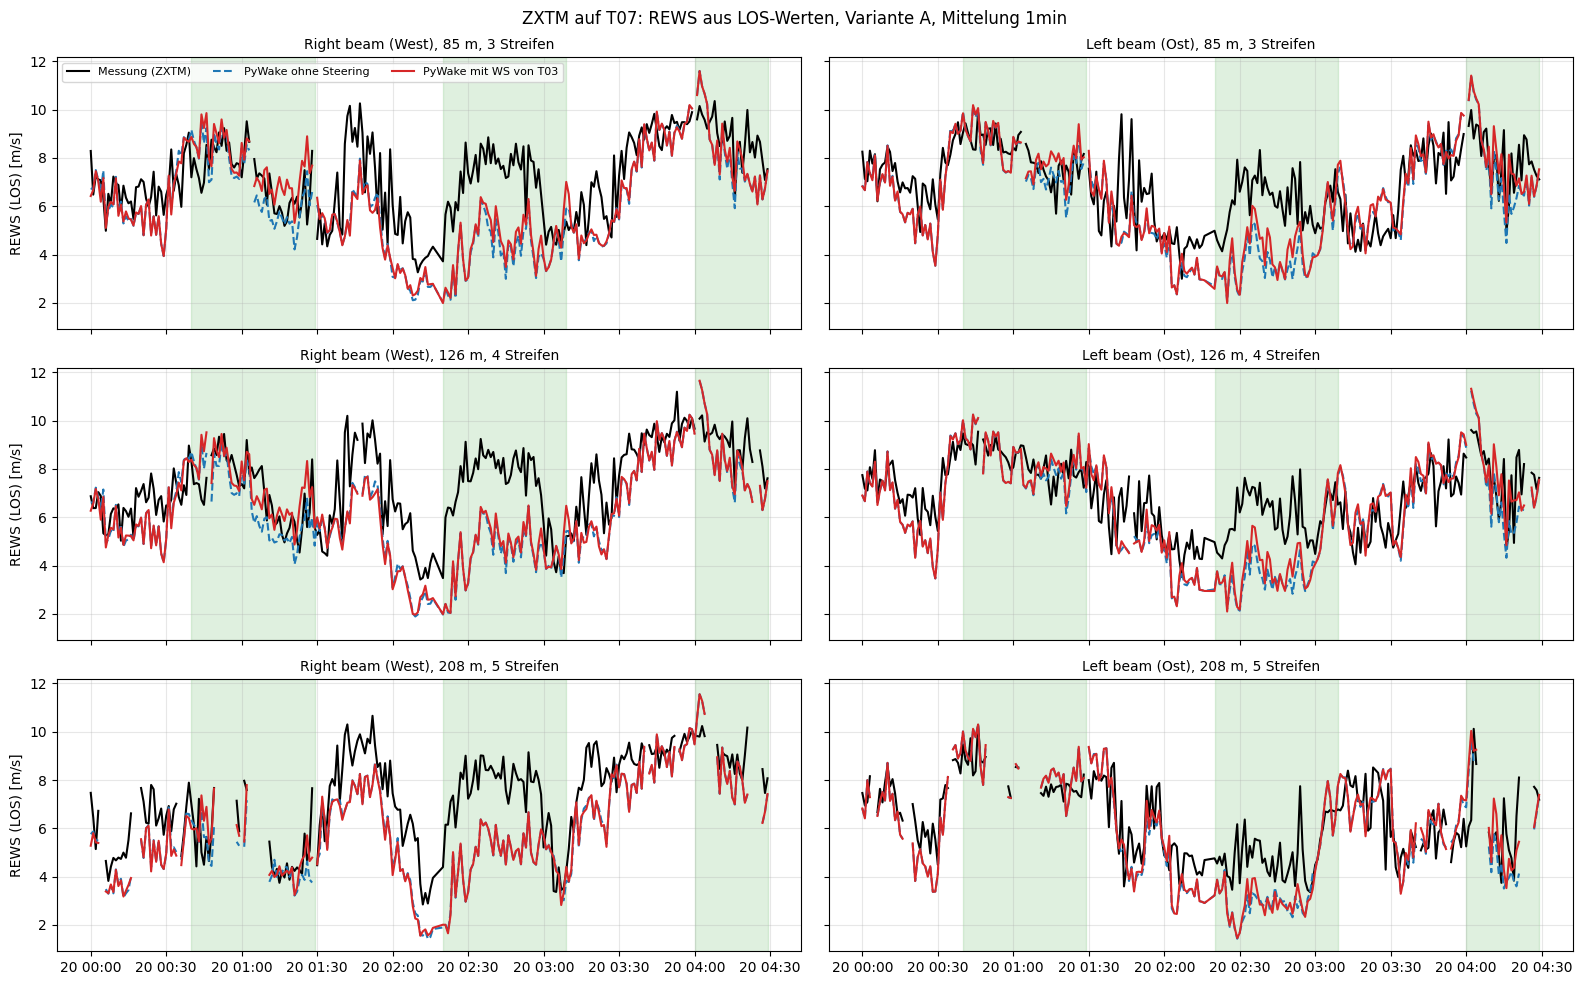

In [25]:
wide = rews_df.pivot_table(index="time", columns=["range", "side"],
                           values=["rews_meas", "rews_ref", "rews_steer"])
toggle_on = m["toggle_on"].reindex(wide.index).fillna(False)

styles = [
    ("rews_meas",  dict(color="black"),             "Messung (ZXTM)"),
    ("rews_ref",   dict(color="tab:blue", ls="--"), "PyWake ohne Steering"),
    ("rews_steer", dict(color="tab:red"),           "PyWake mit WS von T03"),
]

fig, axes = plt.subplots(len(RANGES_M), 2, figsize=(16, 10), sharex=True, sharey=True)
for row, r in enumerate(RANGES_M):
    for col, side in enumerate(SIDES):
        ax = axes[row, col]
        for var, style, label in styles:
            s = wide[(var, r, side)]
            ax.plot(s.index, s, label=label, **style)
        ax.fill_between(wide.index, 0, 1, where=toggle_on, transform=ax.get_xaxis_transform(),  # type: ignore
                        color="tab:green", alpha=0.15)
        ax.set_title(f"{side} beam ({'West' if side == 'Right' else 'Ost'}), {r:.0f} m, "
                     f"{len(REWS_HEIGHTS[r])} Streifen", fontsize=10)
        ax.grid(alpha=0.3)
        if col == 0:
            ax.set_ylabel("REWS (LOS) [m/s]")
axes[0, 0].legend(ncol=3, fontsize=8)
axes[0, 0].margins(x=0)
fig.suptitle(f"ZXTM auf T07: REWS aus LOS-Werten, Variante A, Mittelung {FREQ}")
fig.tight_layout()
plt.show()

### 11.2 Fehler zerlegt: gleitender Bias, Streuung und RMSE

Es gilt `RMSE² = Bias² + Streuung²`. Ein großer Bias bei kleiner Streuung zeigt einen systematischen Fehler (z. B. zu schwache Anströmung), eine große Streuung bei kleinem Bias eher Messrauschen.

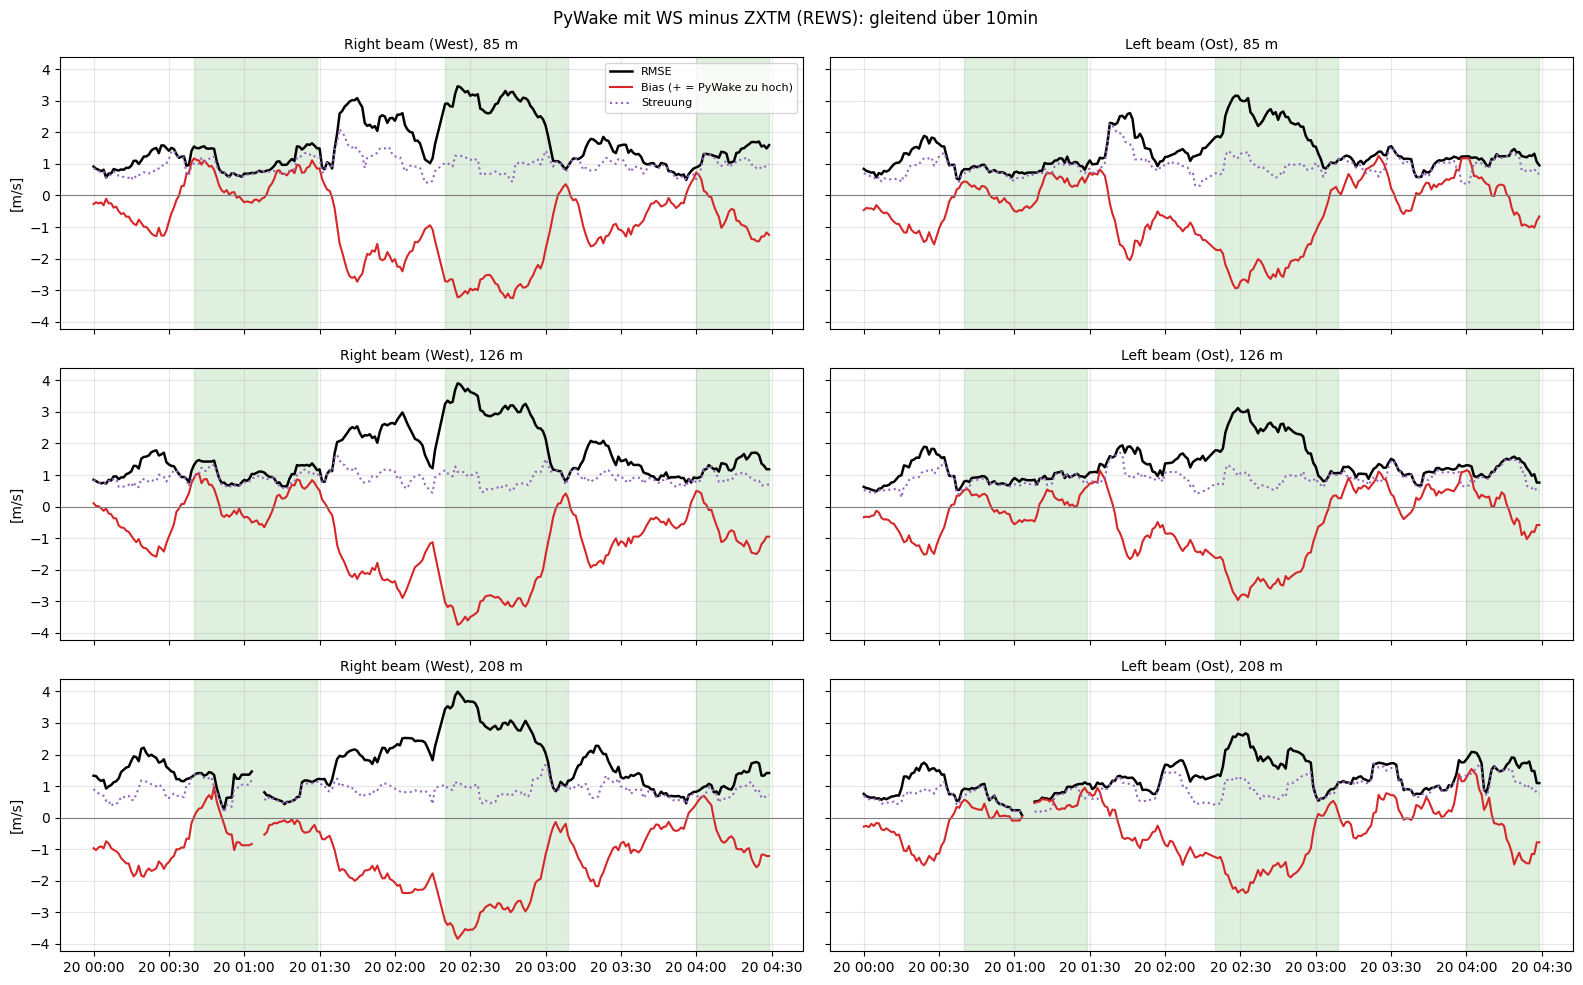

In [26]:
WINDOW = "10min"


def rolling_decomposition(e, window=WINDOW):
    roll = e.rolling(window, center=True, min_periods=3)
    bias = roll.mean()
    spread = roll.std(ddof=0)
    return bias, spread, np.sqrt(bias**2 + spread**2)


err = wide["rews_steer"] - wide["rews_meas"]

fig, axes = plt.subplots(len(RANGES_M), 2, figsize=(16, 10), sharex=True, sharey=True)
for row, r in enumerate(RANGES_M):
    for col, side in enumerate(SIDES):
        ax = axes[row, col]
        bias, spread, rmse_roll = rolling_decomposition(err[(r, side)])
        ax.plot(rmse_roll.index, rmse_roll, color="black", lw=1.8, label="RMSE")
        ax.plot(bias.index, bias, color="tab:red", lw=1.5, label="Bias (+ = PyWake zu hoch)")
        ax.plot(spread.index, spread, color="tab:purple", ls=":", lw=1.5, label="Streuung")
        ax.axhline(0, color="grey", lw=0.8)
        ax.fill_between(wide.index, 0, 1, where=toggle_on, transform=ax.get_xaxis_transform(),  # type: ignore
                        color="tab:green", alpha=0.15)
        ax.set_title(f"{side} beam ({'West' if side == 'Right' else 'Ost'}), {r:.0f} m", fontsize=10)
        ax.grid(alpha=0.3)
        if col == 0:
            ax.set_ylabel("[m/s]")
axes[0, 0].legend(fontsize=8)
axes[0, 0].margins(x=0)
fig.suptitle(f"PyWake mit WS minus ZXTM (REWS): gleitend über {WINDOW}")
fig.tight_layout()
plt.show()

### 11.3 Höhenprofile zu einem Zeitpunkt

Gegenstück zu den Seitenpanels der Referenzabbildung: gemessene und simulierte LOS-Werte pro Höhenstreifen.

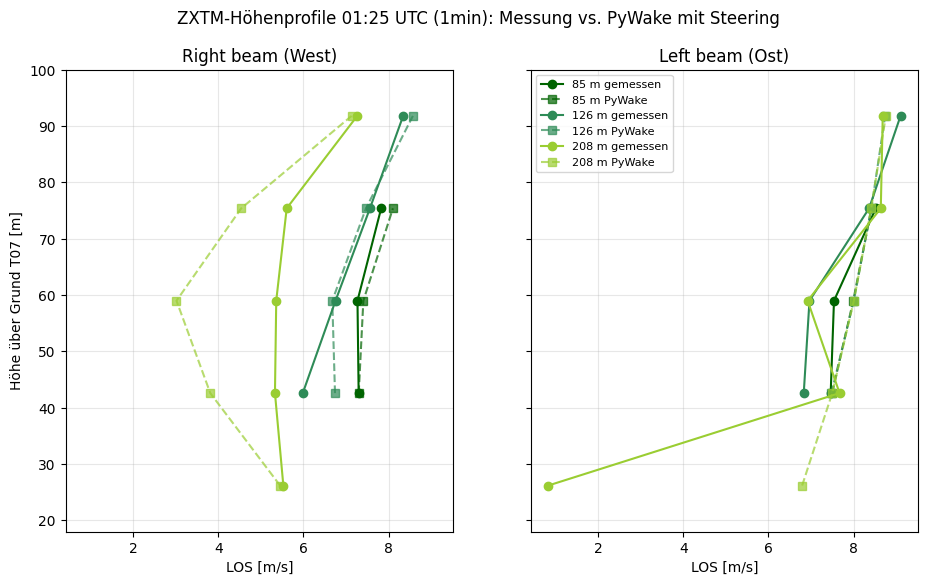

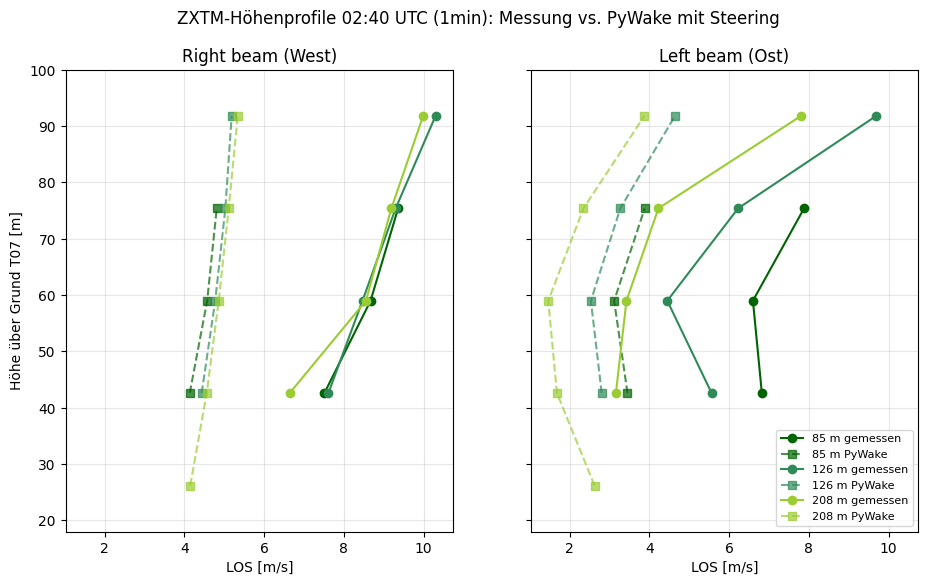

In [27]:
RANGE_COLORS = {85.0: "darkgreen", 126.0: "seagreen", 208.0: "yellowgreen"}


def plot_profiles(t_str):
    ts = pd.Timestamp(t_str, tz="UTC")
    snap = los30[los30["time"] == ts]
    fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharex=True, sharey=True)
    for ax, side in zip(axes, SIDES):
        for r, c in RANGE_COLORS.items():
            d = snap[(snap["side"] == side) & (snap["range"] == r)
                     & (snap["height"].isin(REWS_HEIGHTS[r]))].sort_values("height")
            ax.plot(d["los_meas"], d["height"], "o-", color=c, label=f"{r:.0f} m gemessen")
            ax.plot(d["los_steer"], d["height"], "s--", color=c, alpha=0.7, label=f"{r:.0f} m PyWake")
        ax.set_title(f"{side} beam ({'West' if side == 'Right' else 'Ost'})")
        ax.set_xlabel("LOS [m/s]")
        ax.set_ylim(18, 100)
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("Höhe über Grund T07 [m]")
    axes[1].legend(fontsize=8)
    fig.suptitle(f"ZXTM-Höhenprofile {ts:%H:%M} UTC ({FREQ}): Messung vs. PyWake mit Steering")
    plt.show()


plot_profiles("2026-02-20 01:25")
plot_profiles("2026-02-20 02:40")

### 11.4 Draufsicht: Flow Map mit den Messpunkten

Kontrolle der Geometrie: Liegen die Messpunkte zwischen T03 und T07, und wie liegt der simulierte Nachlauf von T03 relativ zu ihnen?

WARNING matplotlib.axes._base: Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


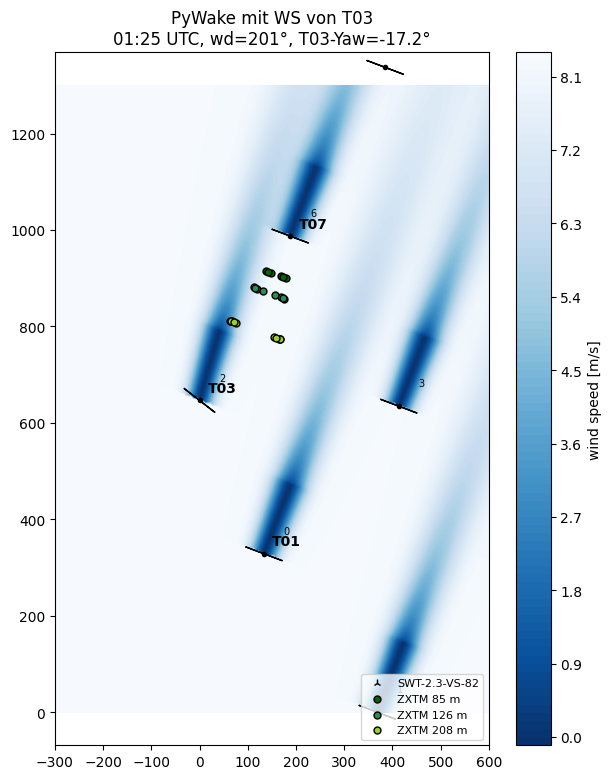

WARNING matplotlib.axes._base: Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


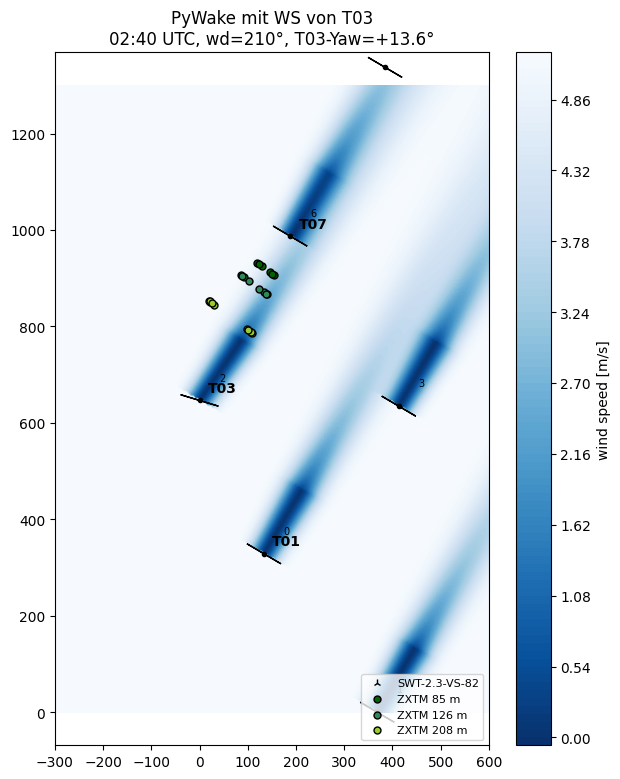

In [28]:
def plot_flowmap_with_points(t_str, sim=sim_steer, title="PyWake mit WS von T03"):
    ts = pd.Timestamp(t_str, tz="UTC")
    i_t = m.index.get_loc(ts)
    grid = HorizontalGrid(x=np.linspace(-300, 600, 180), y=np.linspace(0, 1300, 260))
    fm = sim.flow_map(grid=grid, time=time[i_t])

    fig, ax = plt.subplots(figsize=(7, 9))
    fm.plot_wake_map(ax=ax)
    pts = pd.DataFrame(zxtm_points_3d(m["yaw_t07"].iloc[i_t]))
    for r, c in RANGE_COLORS.items():
        p = pts[(pts["range"] == r) & (pts["height"].isin(REWS_HEIGHTS[r]))]
        ax.scatter(p["x"], p["y"], color=c, edgecolor="k", s=25, zorder=5, label=f"ZXTM {r:.0f} m")
    for n in ["T01", "T03", "T07"]:
        i = names.index(n)
        ax.annotate(n, (x[i], y[i]), xytext=(6, 6), textcoords="offset points", fontweight="bold")
    ax.set_xlim(-300, 600)
    ax.set_ylim(0, 1300)
    ax.set_aspect("equal")
    ax.legend(fontsize=8, loc="lower right")
    ax.set_title(f"{title}\n{ts:%H:%M} UTC, wd={wd_in[i_t]:.0f}°, T03-Yaw={m['yaw_mis_t03'].iloc[i_t]:+.1f}°")
    plt.show()


plot_flowmap_with_points("2026-02-20 01:25")
plot_flowmap_with_points("2026-02-20 02:40")

## Offene Punkte

- **Geometrie (ZXTM):** Ist `Range` der Abstand entlang der Rotorachse oder entlang des Strahls? Wie werden Abtastpunkte nahe dem obersten/untersten Kreispunkt links/rechts zugeordnet (betrifft nur 126 m / 91.8 m)? Welche Verweilzeiten pro Distanz?
- **Windscherung:** `SHEAR_ALPHA` aus dem ZX300 bestimmen (`add_shear_and_veer` in `lidar_helpers.py`).
- **Veer** (Drehung der Windrichtung mit der Höhe) ist noch nicht berücksichtigt. Erst messen, ob er im Zeitraum relevant ist.
- **Anströmung:** T01 liefert in manchen Phasen zu wenig Wind für T03/T07. Alternativen prüfen (andere Referenzturbine, ZX300).
- **Wake-Parameter** `WAKE_K` und `TI` an die hohe Turbulenz des Standorts anpassen.
- **Zeitliche Mittelung:** `FREQ = "10min"` ausprobieren.
- **REWS aus LOS** ist eine LOS-Variante der Norm-REWS (die Norm verwendet horizontale Windgeschwindigkeiten).

# 12. Kann ein Offset den Fehler minimieren?

In [29]:
quick = pd.DataFrame({
    "rmse": stats[("steer", "rmse")],
    "bias": stats[("steer", "bias")],
})
quick["rmse_ohne_bias"] = np.sqrt(quick["rmse"] ** 2 - quick["bias"] ** 2)
quick["verbesserung_%"] = 100 * (1 - quick["rmse_ohne_bias"] / quick["rmse"])
quick.round(3)

rmse   bias  rmse_ohne_bias  verbesserung_%
range side                                               
85.0  Left   1.498 -0.511           1.408           5.998
      Right  1.797 -0.913           1.548          13.868
126.0 Left   1.452 -0.469           1.374           5.360
      Right  1.854 -1.083           1.505          18.835
208.0 Left   1.376 -0.405           1.315           4.430
      Right  1.912 -1.326           1.377          27.956

In [33]:
meas_df = pd.concat(meas)   # Messwerte aus Abschnitt 8, einmal vorbereiten


def simulate_los(ws_factor=1.0, ws_add=0.0, yaw_matrix=yaw):
    """PyWake mit korrigierter Anströmung rechnen, an den ZXTM-Punkten auswerten, auf LOS projizieren."""
    ws_mod = np.clip(ws_in * ws_factor + ws_add, 0.1, None)
    sim = wf_model(x, y, wd=wd_in, ws=ws_mod, time=time, yaw=yaw_matrix, tilt=0)
    rows = []
    for i_t, ts in enumerate(m.index):
        yaw07 = m["yaw_t07"].iloc[i_t]
        pts = zxtm_points_3d(yaw07)
        grid = Points(np.array([p["x"] for p in pts]),
                      np.array([p["y"] for p in pts]),
                      np.array([p["z"] for p in pts]))
        ws_pts = sim.flow_map(grid=grid, time=time[i_t]).WS_eff.values.ravel()
        delta = np.deg2rad(wd_in[i_t] - yaw07)
        for p, w_pt in zip(pts, ws_pts):
            proj = p["c_axis"] * np.cos(delta) + p["c_side"] * np.sin(delta)
            rows.append({"time": ts, "range": p["range"], "height": p["height"],
                         "side": p["side"], "los_sim": w_pt * proj})
    return pd.DataFrame(rows).merge(meas_df, on=["time", "range", "height", "side"], how="left")


def compute_rews(los_df, value_cols):
    """REWS pro Intervall aus den vorhandenen Streifen (min. 3 inkl. Nabenhöhe), Gewichte nach Variante A."""
    parts = []
    for (r, side), g in los_df.groupby(["range", "side"]):
        hs_all = REWS_HEIGHTS[r]
        piv = g.pivot(index="time", columns="height", values=value_cols)
        available = piv["los_meas"][hs_all].notna()
        recs = []
        for ts, ok in available.iterrows():
            hs = [h for h in hs_all if ok[h]]
            if len(hs) < MIN_HEIGHTS or 59.0 not in hs:
                continue
            w = rews_weights(hs)
            rec = {"time": ts, "range": r, "side": side}
            for var in value_cols:
                rec[var.replace("los", "rews")] = sum(w[h] * piv.loc[ts, (var, h)] ** 3 for h in hs) ** (1 / 3)
            recs.append(rec)
        parts.append(pd.DataFrame(recs))
    return pd.concat(parts, ignore_index=True)


def mean_nrmse(rews, sim_col):
    """Score: Mittelwert der NRMSE über die 6 Zeitreihen."""
    per_series = rews.groupby(["range", "side"]).apply(lambda g: metrics(g, sim_col), include_groups=False)
    return per_series["nrmse_%"].mean(), per_series

Faktor 0.95: Score 25.19 %, mittlerer Bias -1.09 m/s
Faktor 1.00: Score 23.59 %, mittlerer Bias -0.78 m/s
Faktor 1.05: Score 22.90 %, mittlerer Bias -0.47 m/s
Faktor 1.10: Score 23.23 %, mittlerer Bias -0.15 m/s
Faktor 1.15: Score 24.60 %, mittlerer Bias +0.18 m/s
Faktor 1.20: Score 26.95 %, mittlerer Bias +0.52 m/s
Faktor 1.25: Score 30.13 %, mittlerer Bias +0.86 m/s
Faktor 1.30: Score 33.98 %, mittlerer Bias +1.22 m/s


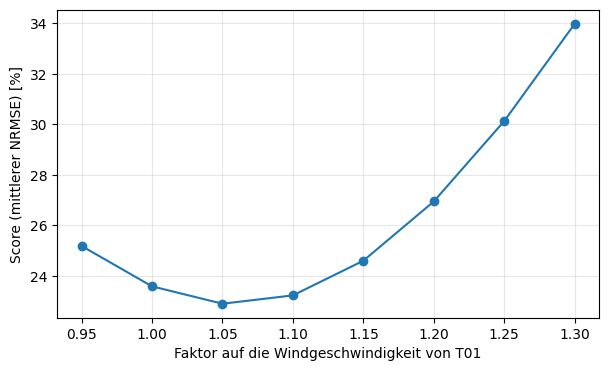

In [34]:
factors = [0.95, 1.00, 1.05, 1.10, 1.15, 1.20, 1.25, 1.30]

results = []
for f in factors:
    rews_f = compute_rews(simulate_los(ws_factor=f), ["los_meas", "los_sim"])
    score_f, _ = mean_nrmse(rews_f, "rews_sim")
    bias_f = (rews_f["rews_sim"] - rews_f["rews_meas"]).mean()
    results.append({"faktor": f, "score_nrmse_%": score_f, "mittlerer_bias": bias_f})
    print(f"Faktor {f:.2f}: Score {score_f:.2f} %, mittlerer Bias {bias_f:+.2f} m/s")

scan = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(scan["faktor"], scan["score_nrmse_%"], "o-")
ax.set_xlabel("Faktor auf die Windgeschwindigkeit von T01")
ax.set_ylabel("Score (mittlerer NRMSE) [%]")
ax.grid(alpha=0.3)
plt.show()

Offset -0.50 m/s: Score 26.61 %, mittlerer Bias -1.19 m/s
Offset -0.25 m/s: Score 24.96 %, mittlerer Bias -0.99 m/s
Offset +0.00 m/s: Score 23.59 %, mittlerer Bias -0.78 m/s
Offset +0.25 m/s: Score 22.54 %, mittlerer Bias -0.58 m/s
Offset +0.50 m/s: Score 21.86 %, mittlerer Bias -0.37 m/s
Offset +0.75 m/s: Score 21.59 %, mittlerer Bias -0.16 m/s
Offset +1.00 m/s: Score 21.74 %, mittlerer Bias +0.05 m/s
Offset +1.25 m/s: Score 22.31 %, mittlerer Bias +0.26 m/s


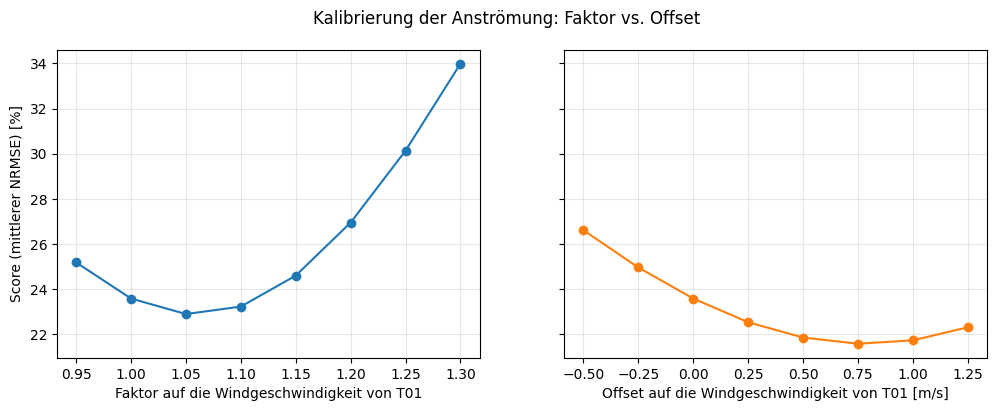

In [35]:
offsets = [-0.5, -0.25, 0.0, 0.25, 0.5, 0.75, 1.0, 1.25]

results_add = []
for a in offsets:
    rews_a = compute_rews(simulate_los(ws_add=a), ["los_meas", "los_sim"])
    score_a, _ = mean_nrmse(rews_a, "rews_sim")
    bias_a = (rews_a["rews_sim"] - rews_a["rews_meas"]).mean()
    results_add.append({"offset": a, "score_nrmse_%": score_a, "mittlerer_bias": bias_a})
    print(f"Offset {a:+.2f} m/s: Score {score_a:.2f} %, mittlerer Bias {bias_a:+.2f} m/s")

scan_add = pd.DataFrame(results_add)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].plot(scan["faktor"], scan["score_nrmse_%"], "o-")
axes[0].set_xlabel("Faktor auf die Windgeschwindigkeit von T01")
axes[0].set_ylabel("Score (mittlerer NRMSE) [%]")
axes[1].plot(scan_add["offset"], scan_add["score_nrmse_%"], "o-", color="tab:orange")
axes[1].set_xlabel("Offset auf die Windgeschwindigkeit von T01 [m/s]")
for ax in axes:
    ax.grid(alpha=0.3)
fig.suptitle("Kalibrierung der Anströmung: Faktor vs. Offset")
plt.show()